In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
cols = list(range(1, 21))

In [3]:
data = pd.read_csv("../temp/Riesengang_descriptors.csv", usecols=cols)

In [4]:
X = data.values
Xmean = np.mean(X, axis=0)
Xstd = np.std(X, axis=0)

Xnormed = (X-Xmean) / Xstd
covX = Xnormed.T @ Xnormed

In [5]:
eigenvalues, eigenvectors = np.linalg.eig(covX)

In [ ]:
descending_order = np.flip(eigenvalues.argsort())

eigenvalues = eigenvalues[descending_order]
eigenvectors = eigenvectors[descending_order]

np.linalg.norm(eigenvectors[0]*np.sqrt(eigenvalues)[0])

[3.02030026e+03 6.47376732e+02 3.12219379e+02 2.33020452e+02
 1.98252955e+02 1.22060683e+02 4.52131597e+01 4.39211461e+01
 1.59731217e+01 7.31570865e+00 5.96781401e+00 2.58775449e+00
 2.12552555e+00 1.58219788e+00 1.04852232e+00 4.96930482e-01
 2.90840923e-01 1.80784782e-01 5.52904479e-02 1.07415414e-02]


54.95725848746442

In [25]:
explained_variance = eigenvalues / np.sum(eigenvalues)
for c, elem in enumerate(explained_variance[:5]):
    print(f"PC {c+1}: {elem*100:.3g}%")

PC 1: 64.8%
PC 2: 13.9%
PC 3: 6.7%
PC 4: 5%
PC 5: 4.25%


In [8]:
reduced_data = np.matmul(Xnormed, eigenvectors[:, :2]) # transform original data. 

In [45]:
from sklearn.decomposition import PCA

In [69]:
features = data.columns
pca  = PCA(n_components=10)
the_components = pca.fit_transform(Xnormed)
the_loadings = pca.components_.T * np.sqrt(pca.explained_variance_)



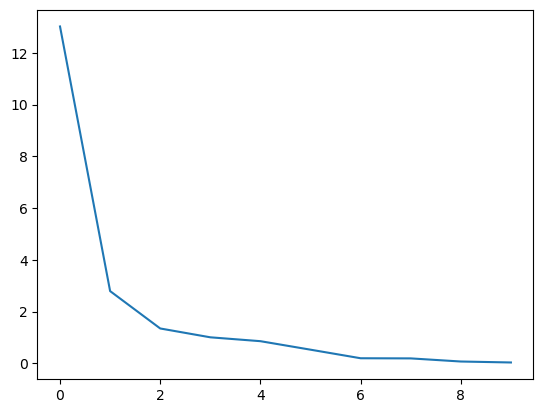

In [70]:
plt.plot(pca.explained_variance_)

In [55]:
pca_loadings = pd.DataFrame(the_loadings, index=features)

In [77]:
pca_loadings

,0,1,2
area,0.349498,0.893816,-0.223789
ellipse_aspect_ratio,0.916698,-0.129266,-0.234781
ellipse_rotation,0.071492,0.315032,0.671224
perimeter,0.869783,0.476694,-0.012370
solidity,-0.613071,-0.108182,-0.638361
hydraulic_diameter,-0.590957,0.727892,-0.295779
max_chord_length,0.950570,0.220984,-0.160986
rmax,0.951984,0.240845,0.020083
rmin,-0.653254,0.616496,0.175675
r_average,0.813677,0.552233,-0.153764


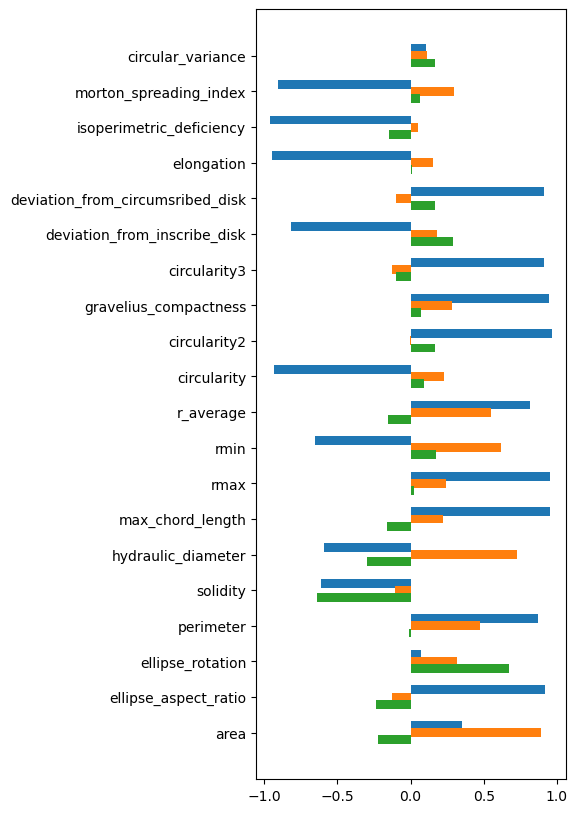

In [93]:
fig, ax = plt.subplots(figsize=(4, 10))


ax.barh( np.arange(20)+0.2, pca_loadings[0], height = 0.25)
ax.barh( np.arange(20), pca_loadings[1], height = 0.25)
ax.barh( np.arange(20)-0.2, pca_loadings[2], height = 0.25)


ax.set_yticks(np.arange(20))
ax.set_yticklabels(pca_loadings.index);

[ 0.34949816  0.89381552 -0.22378892  0.01875347  0.12819186 -0.09329485
 -0.06466721 -0.00101795  0.02705709 -0.00270818]
[ 0.91669771 -0.12926598 -0.23478128  0.0249061  -0.12109007  0.23458639
  0.06205156 -0.05813188 -0.07731866 -0.06762508]
[ 0.07149152  0.31503173  0.67122351  0.17673194  0.52604262  0.37523137
  0.02123129 -0.00954648 -0.00838062 -0.00144709]
[ 0.8697827   0.47669418 -0.0123702  -0.02549378  0.01846386 -0.08090527
 -0.00765985 -0.10787803  0.00776252  0.02436812]
[-0.61307116 -0.1081818  -0.63836072  0.19511444  0.04310392  0.38203342
  0.0567897  -0.10884208  0.02906666  0.08290038]
[-5.90957378e-01  7.27891924e-01 -2.95779016e-01  4.50826113e-02
  1.15001812e-01 -2.87855001e-02  2.07808488e-02  1.35610419e-01
  1.19920257e-04 -3.24059117e-02]
[ 0.95056988  0.22098406 -0.16098596  0.00506289 -0.06444749  0.11805953
 -0.02159381 -0.01051745  0.02706914 -0.01346828]
[ 0.9519839   0.24084508  0.02008345 -0.0475988  -0.07807801  0.06126219
  0.02182467  0.14586351 

(-1.0, 1.0)

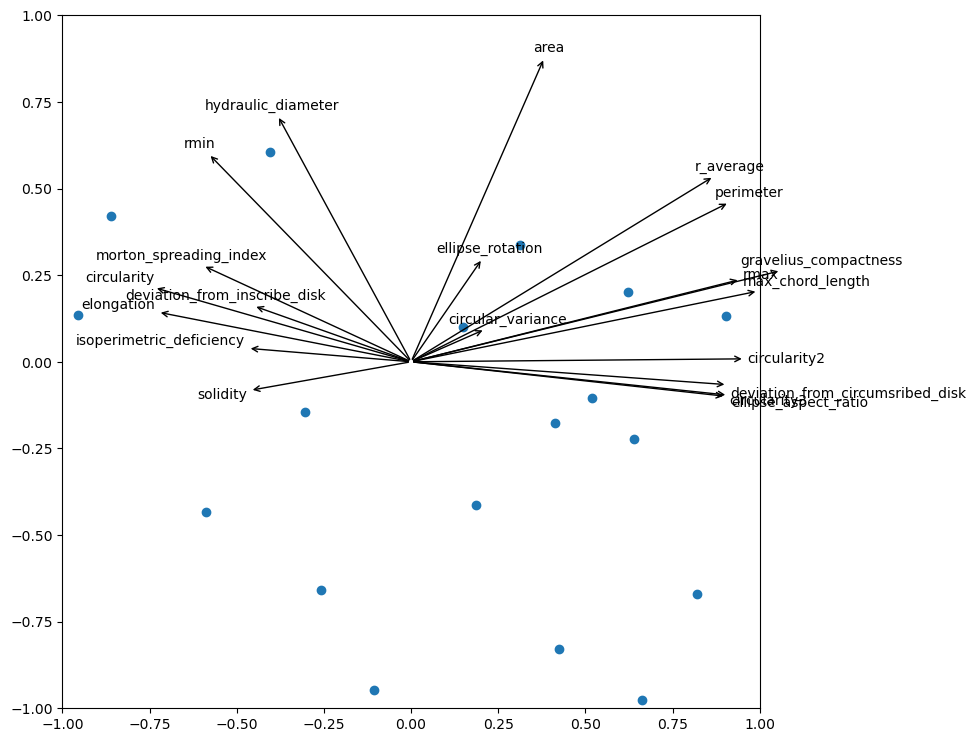

In [76]:
fig, ax = plt.subplots(figsize = (9,9))


ax.scatter(*the_components[:, :2].T)
for c, loading in enumerate(the_loadings):
    print(loading)
    ax.annotate(features[c], xytext=loading[:2], xy=(0,0), arrowprops=dict(arrowstyle="<-"))

ax.set_xlim(-1, 1)
ax.set_ylim(-1, 1)